<a href="https://colab.research.google.com/github/SobiaNoorAI/cxr-foundation-model-shift-robustness/blob/main/notebooks/04_calibration_and_paired_tests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## load

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/phd_projects/cxr_shift"
SEED = 42
df = pd.read_csv(f"{BASE}/metadata.csv")
ENC = ["resnet50_imagenet", "dinov2_base", "rad_dino"]
CLEAN = {k: np.load(f"{BASE}/features/{k}.npy") for k in ENC}
y, hosp = df.label.values, df.hospital.values
DIRS = [("shenzhen", "montgomery"), ("montgomery", "shenzhen")]

Mounted at /content/drive


## train the cross-hospital models

In [2]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

def make_model():
    return make_pipeline(StandardScaler(),
        LogisticRegressionCV(Cs=[0.001, 0.01, 0.1, 1, 10], cv=5,
                             scoring="roc_auc", max_iter=5000, random_state=SEED))

models = {(e, tr): make_model().fit(CLEAN[e][hosp == tr], y[hosp == tr])
          for e in ENC for tr, _ in DIRS}

def scores(enc, tr, te, X=None):
    X = CLEAN[enc] if X is None else X
    return models[(enc, tr)].predict_proba(X[hosp == te])[:, 1]

## calibration table

In [7]:
from sklearn.metrics import brier_score_loss

def ece(yt, p, bins=5):
    edges = np.linspace(0, 1, bins + 1); tot = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p <= hi) if lo == 0 else (p > lo) & (p <= hi)
        if m.sum():
            tot += m.mean() * abs(yt[m].mean() - p[m].mean())
    return tot

rows = []
for e in ENC:
    for tr, te in DIRS:
        p, yt = scores(e, tr, te), y[hosp == te]
        rows.append(dict(encoder=e, direction=f"{tr} → {te}",
                         Brier=brier_score_loss(yt, p), ECE=ece(yt, p),
                         mean_predicted_TB=p.mean(), true_TB_rate=yt.mean()))
cal = pd.DataFrame(rows)
os.makedirs(f"{BASE}/results", exist_ok=True)
cal.round(4).to_csv(f"{BASE}/results/04_calibration.csv", index=False)
cal.round(3)

,encoder,direction,Brier,ECE,mean_predicted_TB,true_TB_rate
0,resnet50_imagenet,shenzhen → montgomery,0.387,0.359,0.702,0.420
1,resnet50_imagenet,montgomery → shenzhen,0.300,0.254,0.504,0.508
2,dinov2_base,shenzhen → montgomery,0.213,0.217,0.210,0.420
3,dinov2_base,montgomery → shenzhen,0.209,0.090,0.417,0.508
4,rad_dino,shenzhen → montgomery,0.075,0.065,0.435,0.420
5,rad_dino,montgomery → shenzhen,0.110,0.086,0.570,0.508


## reliability diagrams

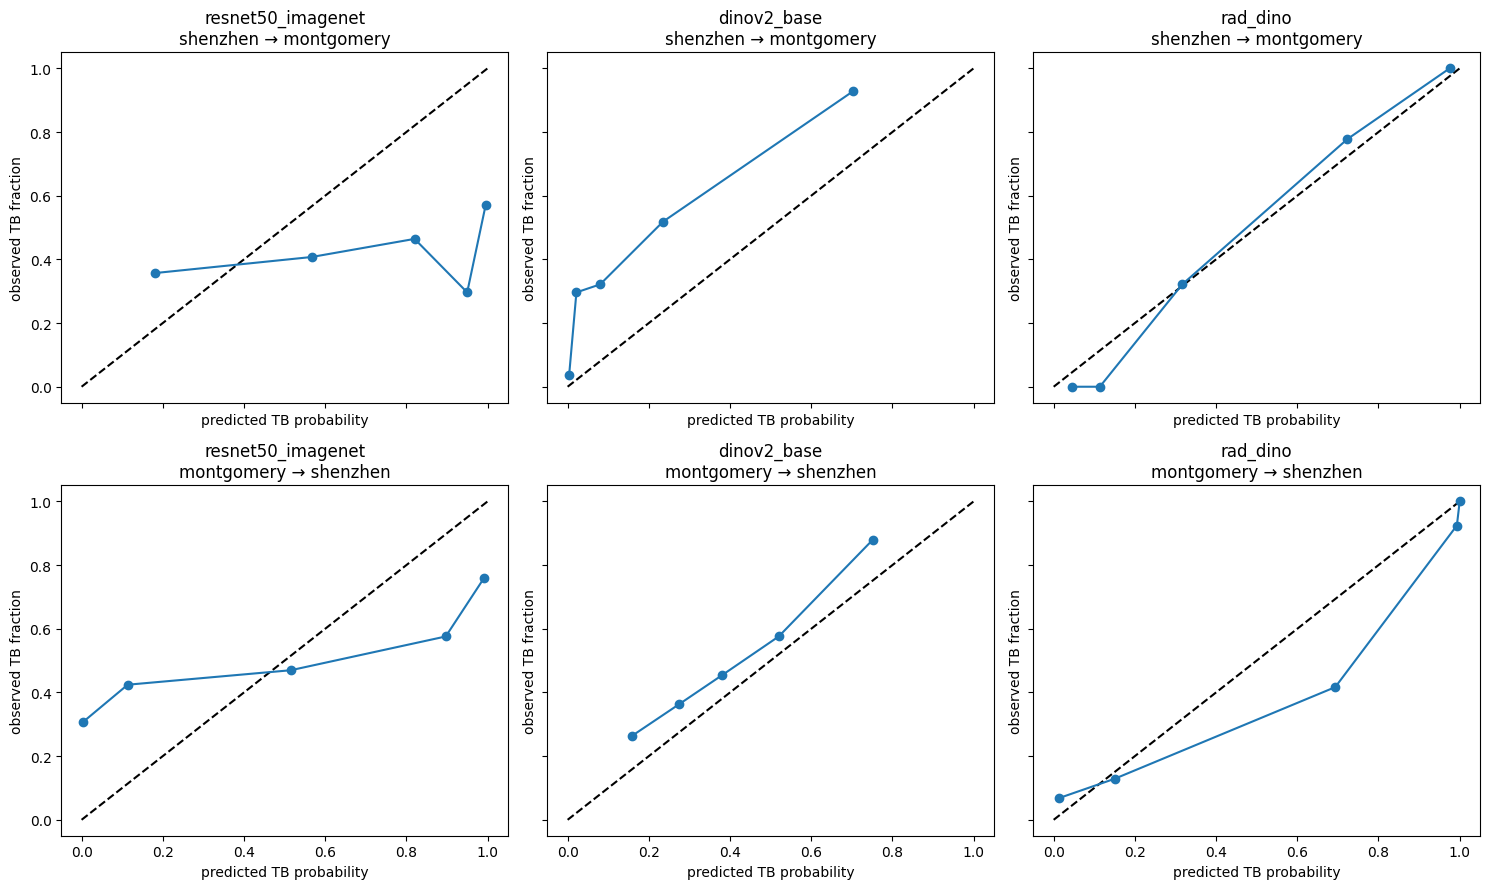

In [8]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for r, (tr, te) in enumerate(DIRS):
    for c, e in enumerate(ENC):
        p, yt = scores(e, tr, te), y[hosp == te]
        frac, mp = calibration_curve(yt, p, n_bins=5, strategy="quantile")
        ax = axes[r, c]
        ax.plot([0, 1], [0, 1], "k--"); ax.plot(mp, frac, marker="o")
        ax.set_title(f"{e}\n{tr} → {te}")
        ax.set_xlabel("predicted TB probability"); ax.set_ylabel("observed TB fraction")
plt.tight_layout()
plt.savefig(f"{BASE}/results/04_reliability.png", dpi=200); plt.show()

abstain when unsure (selective prediction)

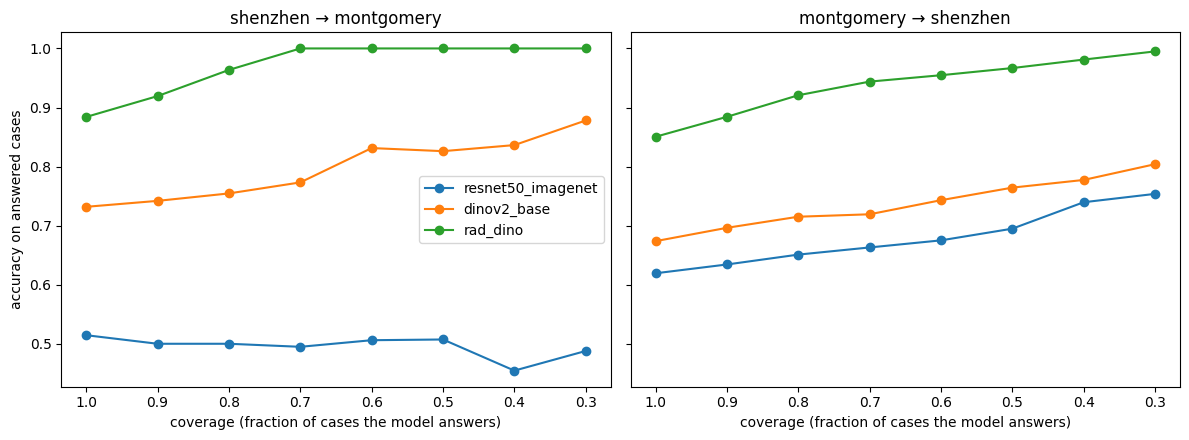

In [9]:
def acc_at_coverage(yt, p, covs):
    conf = np.maximum(p, 1 - p)           # how sure the model is
    order = np.argsort(-conf)             # most confident first
    correct = ((p >= 0.5).astype(int) == yt)[order]
    return [correct[:int(round(c * len(yt)))].mean() for c in covs]

covs = np.round(np.arange(1.0, 0.29, -0.1), 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
sel = []
for ax, (tr, te) in zip(axes, DIRS):
    for e in ENC:
        a = acc_at_coverage(y[hosp == te], scores(e, tr, te), covs)
        ax.plot(covs, a, marker="o", label=e)
        sel += [dict(encoder=e, direction=f"{tr} → {te}", coverage=c, accuracy=v)
                for c, v in zip(covs, a)]
    ax.set_title(f"{tr} → {te}")
    ax.set_xlabel("coverage (fraction of cases the model answers)")
    ax.invert_xaxis()
axes[0].set_ylabel("accuracy on answered cases"); axes[0].legend()
plt.tight_layout()
plt.savefig(f"{BASE}/results/04_selective.png", dpi=200); plt.show()
pd.DataFrame(sel).round(4).to_csv(f"{BASE}/results/04_selective.csv", index=False)

paired bootstrap, clean and corrupted (takes a few minutes)

In [10]:
def paired_boot(yt, sa, sb, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(yt == 1)[0], np.where(yt == 0)[0]
    d = []
    for _ in range(n):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        d.append(roc_auc_score(yt[i], sa[i]) - roc_auc_score(yt[i], sb[i]))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return np.mean(d), lo, hi

CONDS = {"clean": None, "blur-4": "blur_4", "noise-0.12": "noise_0.12",
         "jpeg-8": "jpeg_8", "lowres-64": "lowres_64"}
PAIRS = [("rad_dino", "dinov2_base"), ("rad_dino", "resnet50_imagenet"),
         ("dinov2_base", "resnet50_imagenet")]

rows = []
for cname, f in CONDS.items():
    Z = None if f is None else np.load(f"{BASE}/features_corrupt/{f}.npz")
    for tr, te in DIRS:
        yt = y[hosp == te]
        S = {e: scores(e, tr, te, None if Z is None else Z[e]) for e in ENC}
        for a, b in PAIRS:
            m, lo, hi = paired_boot(yt, S[a], S[b])
            rows.append(dict(condition=cname, direction=f"{tr} → {te}",
                             comparison=f"{a} − {b}", AUROC_diff=m,
                             CI_low=lo, CI_high=hi,
                             clear=("yes" if lo > 0 or hi < 0 else "no")))
paired = pd.DataFrame(rows)
paired.round(3).to_csv(f"{BASE}/results/04_paired_tests.csv", index=False)
paired.round(3)

,condition,direction,comparison,AUROC_diff,CI_low,CI_high,clear
0,clean,shenzhen → montgomery,rad_dino − dinov2_base,0.135,0.071,0.203,yes
1,clean,shenzhen → montgomery,rad_dino − resnet50_imagenet,0.415,0.320,0.517,yes
2,clean,shenzhen → montgomery,dinov2_base − resnet50_imagenet,0.280,0.167,0.388,yes
3,clean,montgomery → shenzhen,rad_dino − dinov2_base,0.192,0.157,0.228,yes
4,clean,montgomery → shenzhen,rad_dino − resnet50_imagenet,0.263,0.223,0.301,yes
5,clean,montgomery → shenzhen,dinov2_base − resnet50_imagenet,0.071,0.024,0.115,yes
6,blur-4,shenzhen → montgomery,rad_dino − dinov2_base,0.167,0.085,0.254,yes
7,blur-4,shenzhen → montgomery,rad_dino − resnet50_imagenet,0.519,0.412,0.629,yes
8,blur-4,shenzhen → montgomery,dinov2_base − resnet50_imagenet,0.352,0.224,0.480,yes
9,blur-4,montgomery → shenzhen,rad_dino − dinov2_base,0.105,0.059,0.148,yes
